<div style="background-color: #4b3832; padding: 20px; border-radius: 10px; box-shadow: 5px 5px 10px #888888;">
  <h1 style="color: white; font-size: 30px; font-weight: bold; text-align: center; text-shadow: 2px 2px 4px #000000;">student_perormance🤓👁‍🗨||+81 r2 score</h1>
</div>

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings 
warnings.filterwarnings('ignore')
data=pd.read_csv('/kaggle/input/student-performance-factors/StudentPerformanceFactors.csv')


In [2]:
data

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [3]:
data.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [4]:
data.isna().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [5]:
data.dropna(inplace=True)

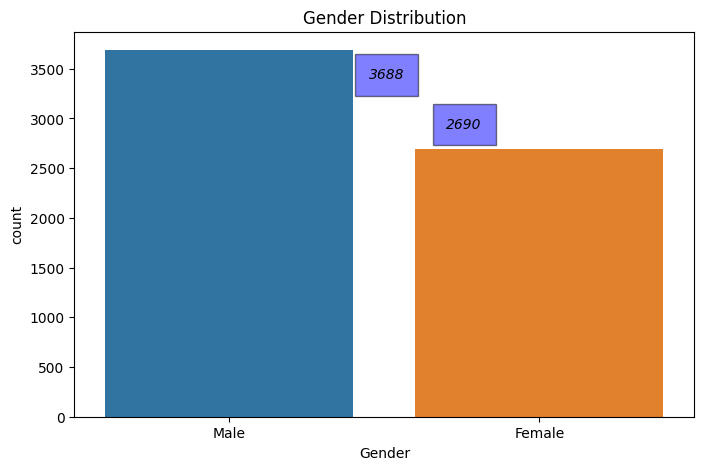

In [6]:
plt.figure(figsize=(8,5))
plt.title('Gender Distribution')
plt.text(0.7, 2900,'2690', style='italic',
        bbox={'facecolor': 'blue', 'alpha': 0.5, 'pad': 10})
plt.text(0.45, 3400,'3688', style='italic',
        bbox={'facecolor': 'blue', 'alpha': 0.5, 'pad': 10})
sns.countplot(x='Gender',data=data)
plt.show()

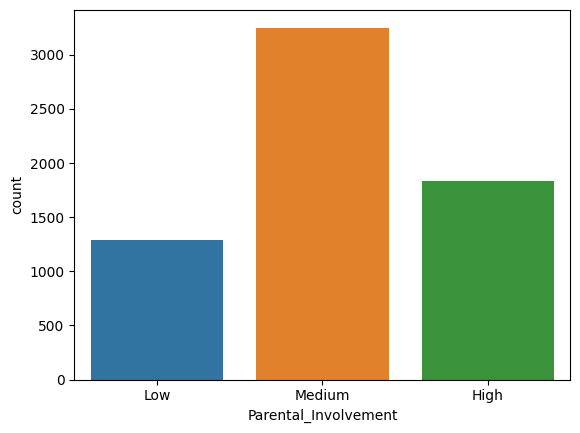

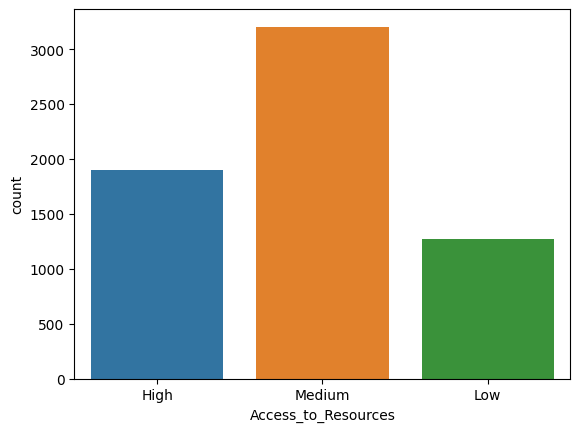

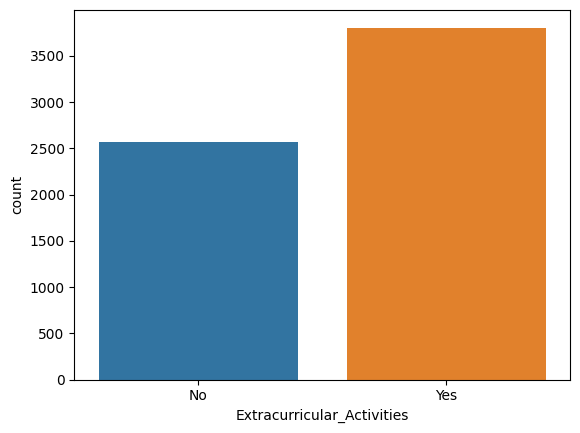

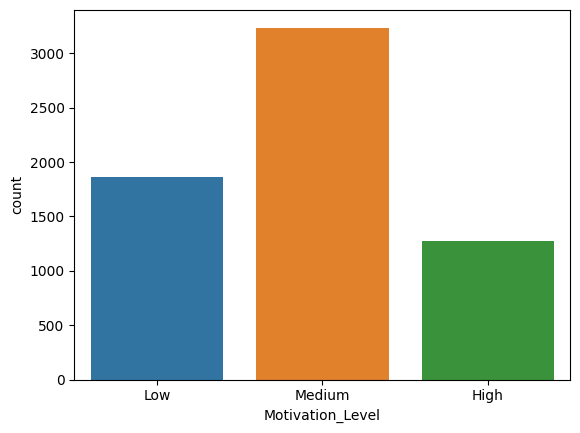

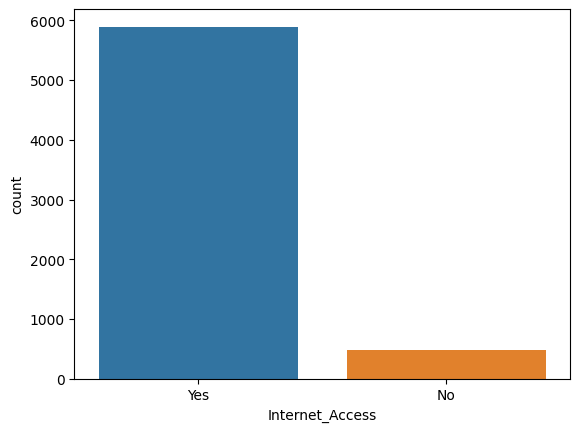

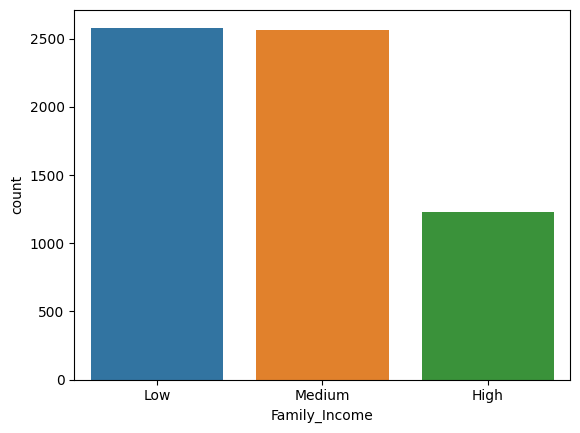

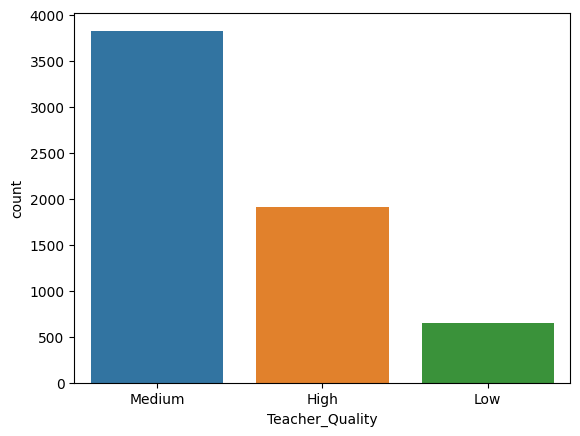

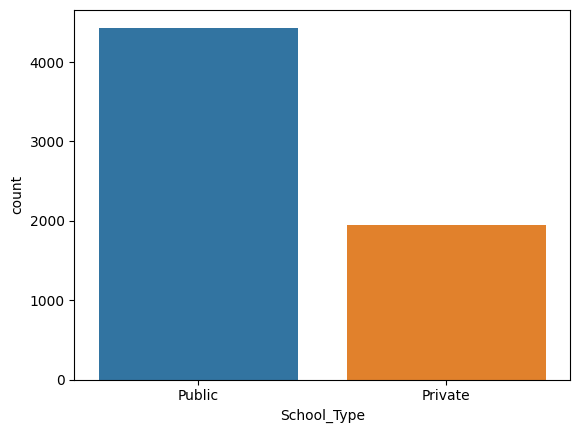

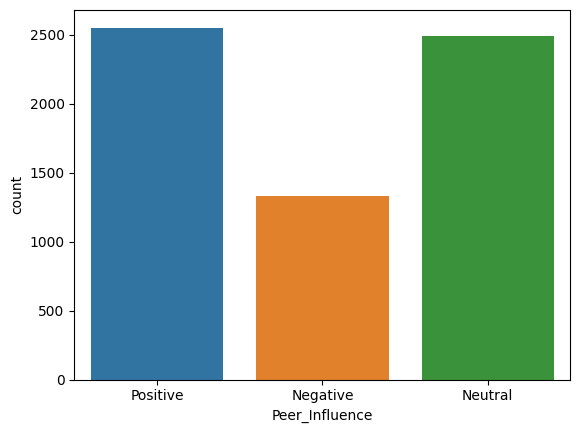

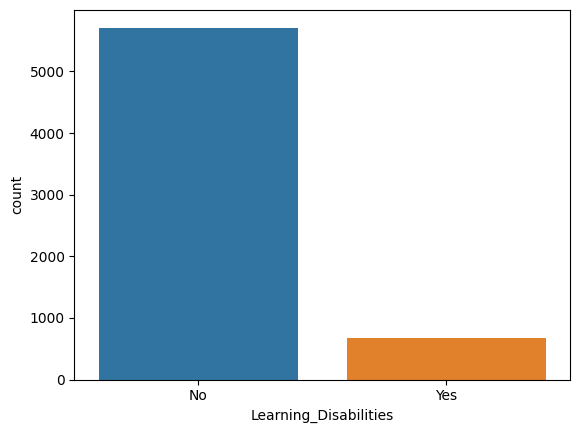

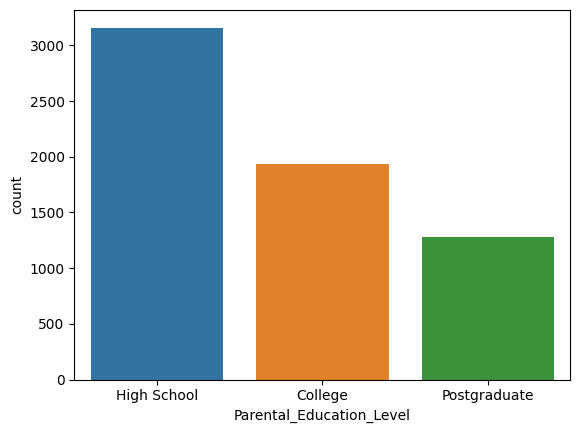

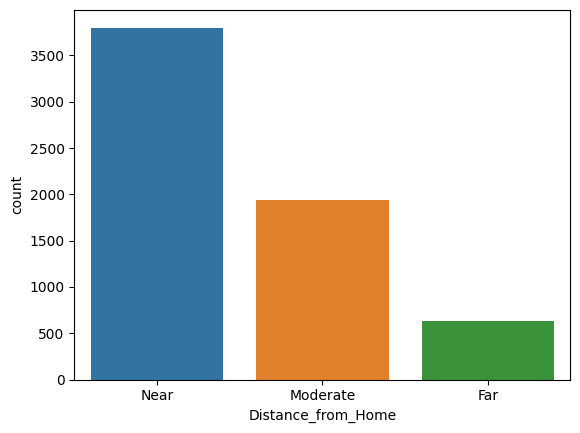

In [7]:
for col in data.select_dtypes(include=['object']).columns:
    if col=='Gender':
        pass
    else:
     sns.countplot(x=col,data=data)
     plt.show()


In [8]:
from sklearn.preprocessing import LabelEncoder
lb=LabelEncoder()

In [9]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in data.columns:
  data[col] = le.fit_transform(data[col])

# I previously trained the model and noted the columns with high correlation.
# So I increase the weight of columns with high cof to get better result.

In [10]:
data['Attendance*Previous_Scores']=data['Attendance'].values*data['Previous_Scores'].values
data['Hours_Studied*Previous_Scores']=data['Hours_Studied'].values*data['Previous_Scores'].values
data['Hours_Studied*Attendance']=data['Hours_Studied'].values*data['Attendance'].values
data['Sleep_Hours*Previous_Scores']=data['Sleep_Hours'].values*data['Previous_Scores'].values
data['Attendance*Previous_Scores']=data['Attendance'].values*data['Previous_Scores'].values


data['Attendance**2']=data['Attendance']**2
data['Previous_Scores**2']=data['Previous_Scores']**2
data['Hours_Studied**2']=data['Hours_Studied']**2
data['Sleep_Hours**2']=data['Sleep_Hours']**2

data['Attendance/2']=data['Attendance']**2
data['Previous_Scores/2']=data['Previous_Scores']/2
data['Hours_Studied/2']=data['Hours_Studied']/2
data['Sleep_Hours/2']=data['Sleep_Hours']/2


data

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Hours_Studied*Attendance,Sleep_Hours*Previous_Scores,Attendance**2,Previous_Scores**2,Hours_Studied**2,Sleep_Hours**2,Attendance/2,Previous_Scores/2,Hours_Studied/2,Sleep_Hours/2
0,22,24,1,0,0,3,23,1,1,0,...,528,69,576,529,484,9,576,11.5,11.0,1.5
1,18,4,1,2,0,4,9,1,1,2,...,72,36,16,81,324,16,16,4.5,9.0,2.0
2,23,38,2,2,1,3,41,2,1,2,...,874,123,1444,1681,529,9,1444,20.5,11.5,1.5
3,28,29,1,2,1,4,48,2,1,1,...,812,192,841,2304,784,16,841,24.0,14.0,2.0
4,18,32,2,2,1,2,15,2,1,3,...,576,30,1024,225,324,4,1024,7.5,9.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,24,9,0,2,0,3,26,2,1,1,...,216,78,81,676,576,9,81,13.0,12.0,1.5
6603,22,16,0,2,0,4,31,2,1,3,...,352,124,256,961,484,16,256,15.5,11.0,2.0
6604,19,30,2,1,1,2,15,1,1,3,...,570,30,900,225,361,4,900,7.5,9.5,1.0
6605,9,26,0,0,1,2,41,0,1,2,...,234,82,676,1681,81,4,676,20.5,4.5,1.0


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn import metrics


In [12]:
x=data.drop('Exam_Score',axis=1)
y=data['Exam_Score']

In [13]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=1)

In [14]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

# LinearRegression

In [15]:
model=LinearRegression(n_jobs=10)
model.fit(x_train,y_train)

LinearRegression(n_jobs=10)

In [16]:
y_pred=model.predict(x_test)

In [17]:
LinRR2=metrics.r2_score(y_test,y_pred)

In [18]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold

In [19]:
k_fold = KFold(10)

In [20]:
print(cross_val_score(model, x,y.ravel(), cv = k_fold, n_jobs = 1))

[0.55286267 0.60378659 0.72437935 0.6018732  0.6030042  0.68815065
 0.60910859 0.74321429 0.89498092 0.68227453]


In [21]:
from sklearn.tree import DecisionTreeRegressor

# DecisionTreeRegressor

In [22]:
dtModel=DecisionTreeRegressor(max_depth=3)
dtModel.fit(x_train,y_train)
dty_pred=dtModel.predict(x_test)

In [23]:
dtRR2=metrics.r2_score(y_test,dty_pred)
dtRR2

0.5431565216657617

# RandomForestRegressor

In [24]:
from sklearn.ensemble import RandomForestRegressor
rfModel=RandomForestRegressor()
rfModel.fit(x_train,y_train)

RandomForestRegressor()

In [25]:
rfModel.score(x_test,y_test)

0.7062300326372604

In [26]:
RFy_pred=rfModel.predict(x_test)

In [27]:
RFR2=metrics.r2_score(y_test,RFy_pred)
RFR2

0.7062300326372604

In [28]:
from sklearn.svm import SVR

# SVR

In [29]:
svrModel=SVR(kernel='linear',max_iter=1)
svrModel.fit(x_train,y_train)

SVR(kernel='linear', max_iter=1)

In [30]:
SVRy_pred=rfModel.predict(x_test)

In [31]:
SVRR2=metrics.r2_score(y_test,SVRy_pred)
SVR

sklearn.svm._classes.SVR

# XGBRegressor

In [32]:
from xgboost import XGBRegressor

In [33]:
xgb=XGBRegressor()
xgb.fit(x_train,y_train)
xgby_pred=xgb.predict(x_test)

In [34]:
xgbR2=metrics.r2_score(y_test,xgby_pred)
xgbR2

0.7524013456492417

# Ridge

In [35]:
from sklearn.linear_model import Ridge

In [36]:
ridge = Ridge(alpha=1.0)
ridge.fit(x_train, y_train)
Ridgy_pred = ridge.predict(x_test)

In [37]:
RIDGr2=metrics.r2_score(y_test,Ridgy_pred)
RIDGr2

0.7575203308461889

# catboost

In [38]:
import catboost as cb

In [39]:
train_dataset = cb.Pool(x_train, y_train) 

In [40]:
catmodel = cb.CatBoostRegressor(loss_function='RMSE')

In [41]:
grid = {'iterations': [100, 150, 200],
        'learning_rate': [0.03, 0.1],
        'depth': [2, 4, 6, 8],
        'l2_leaf_reg': [0.2, 0.5, 1, 3]}
result=catmodel.grid_search(grid, train_dataset)

0:	learn: 12.5199124	test: 12.6014558	best: 12.6014558 (0)	total: 51.6ms	remaining: 5.11s
1:	learn: 12.1700065	test: 12.2502512	best: 12.2502512 (1)	total: 52.7ms	remaining: 2.58s
2:	learn: 11.8389796	test: 11.9181733	best: 11.9181733 (2)	total: 53.6ms	remaining: 1.73s
3:	learn: 11.5129386	test: 11.5914596	best: 11.5914596 (3)	total: 54.5ms	remaining: 1.31s
4:	learn: 11.1996410	test: 11.2759763	best: 11.2759763 (4)	total: 55.5ms	remaining: 1.05s
5:	learn: 10.8960509	test: 10.9707851	best: 10.9707851 (5)	total: 56.4ms	remaining: 884ms
6:	learn: 10.6004416	test: 10.6744914	best: 10.6744914 (6)	total: 57.4ms	remaining: 763ms
7:	learn: 10.3104596	test: 10.3837141	best: 10.3837141 (7)	total: 58.3ms	remaining: 671ms
8:	learn: 10.0343261	test: 10.1060857	best: 10.1060857 (8)	total: 59.2ms	remaining: 599ms
9:	learn: 9.7626380	test: 9.8317908	best: 9.8317908 (9)	total: 60.2ms	remaining: 542ms
10:	learn: 9.5031800	test: 9.5711671	best: 9.5711671 (10)	total: 61.1ms	remaining: 494ms
11:	learn: 9.2

In [42]:
catpred = catmodel.predict(x_test)
catr2 = metrics.r2_score(y_test, catpred)
print(catr2)

0.8104661811376971


# which one is the best

In [43]:
compar=pd.DataFrame(columns=["algorithm","r2"])
compar.loc[len(compar)] = ['LinearRegression', LinRR2]
compar.loc[len(compar)] = ['RandomForestRegressor', RFR2]
compar.loc[len(compar)] = ['XGBRegressor', xgbR2]
compar.loc[len(compar)] = ['Ridge', RIDGr2]
compar.loc[len(compar)] = ['DecisionTreeRegressor', dtRR2]
compar.loc[len(compar)] = ['catboost', catr2]

In [44]:
comparTest=pd.DataFrame(columns=["algorithm","testScore"])
comparTest.loc[len(comparTest)] = ['LinearRegression', model.score(x_test,y_test)]
comparTest.loc[len(comparTest)] = ['RandomForestRegressor', rfModel.score(x_test,y_test)]
comparTest.loc[len(comparTest)] = ['XGBRegressor', xgb.score(x_test,y_test)]
comparTest.loc[len(comparTest)] = ['Ridge', ridge.score(x_test,y_test)]
comparTest.loc[len(comparTest)] = ['DecisionTreeRegressor', dtModel.score(x_test,y_test)]
comparTest.loc[len(comparTest)] = ['catboost', catmodel.score(x_test,y_test)]

In [45]:
comparTrain=pd.DataFrame(columns=["algorithm","trainScore"])
comparTrain.loc[len(comparTrain)] = ['LinearRegression', model.score(x_train,y_train)]
comparTrain.loc[len(comparTrain)] = ['RandomForestRegressor', rfModel.score(x_train,y_train)]
comparTrain.loc[len(comparTrain)] = ['XGBRegressor', xgb.score(x_train,y_train)]
comparTrain.loc[len(comparTrain)] = ['Ridge', ridge.score(x_train,y_train)]
comparTrain.loc[len(comparTrain)] = ['DecisionTreeRegressor', dtModel.score(x_train,y_train)]
comparTrain.loc[len(comparTrain)] = ['catboost', catmodel.score(x_train,y_train)]

In [46]:
compar

,algorithm,r2
0,LinearRegression,0.757546
1,RandomForestRegressor,0.706230
2,XGBRegressor,0.752401
3,Ridge,0.757520
4,DecisionTreeRegressor,0.543157
5,catboost,0.810466


In [47]:
comparTest

,algorithm,testScore
0,LinearRegression,0.757546
1,RandomForestRegressor,0.706230
2,XGBRegressor,0.752401
3,Ridge,0.757520
4,DecisionTreeRegressor,0.543157
5,catboost,0.810466


In [48]:
comparTrain

,algorithm,trainScore
0,LinearRegression,0.648829
1,RandomForestRegressor,0.948089
2,XGBRegressor,0.990966
3,Ridge,0.648898
4,DecisionTreeRegressor,0.513152
5,catboost,0.789602


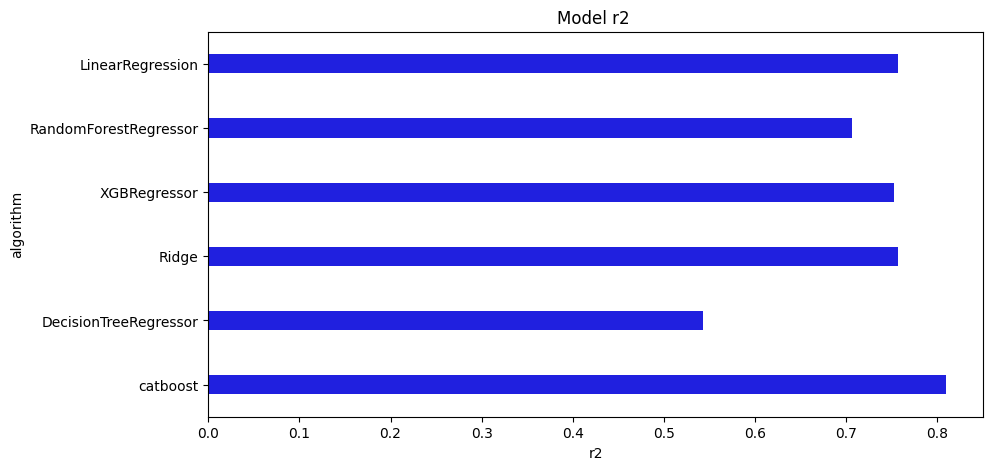

In [49]:
plt.figure(figsize=[10,5])
plt.title('Model r2 ')
sns.barplot(x='r2', y='algorithm', data=compar ,width=0.3,color='blue')
plt.show()

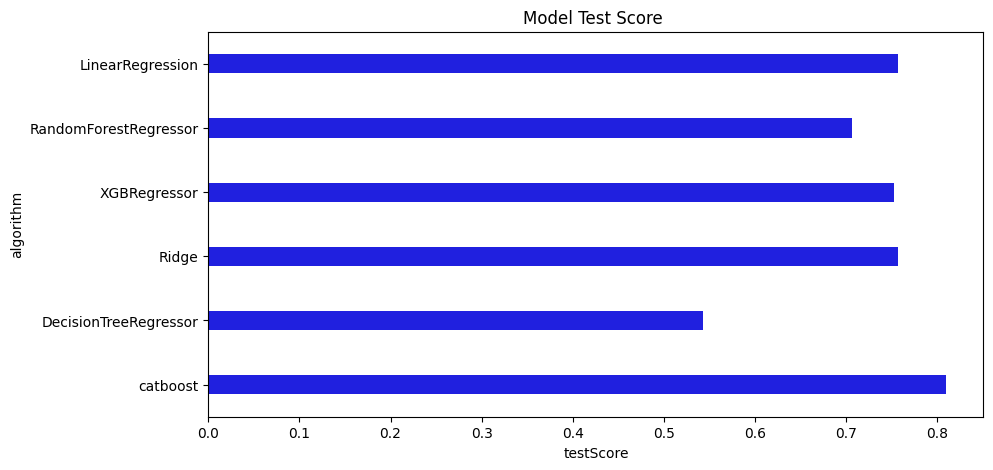

In [50]:
plt.figure(figsize=[10,5])
plt.title('Model Test Score ')
sns.barplot(x='testScore', y='algorithm', data=comparTest ,width=0.3,color='blue')
plt.show()

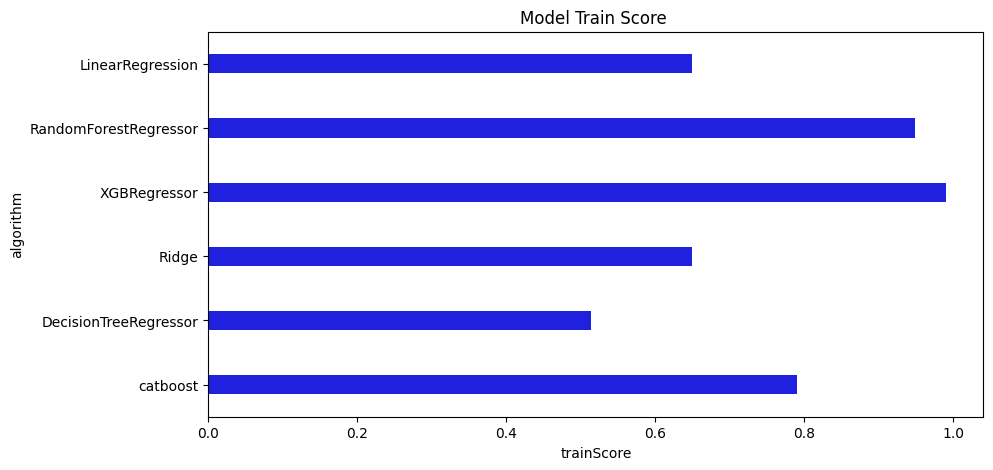

In [51]:
plt.figure(figsize=[10,5])
plt.title('Model Train Score ')
sns.barplot(x='trainScore', y='algorithm', data=comparTrain ,width=0.3,color='blue')
plt.show()

# <h1>Thank you<h1>